# Network exploration

In [2]:
# All the imports
from pathlib import Path
import pandas as pd
import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import time, random
from scipy.stats import spearmanr

In [3]:
DATA_CANDIDATES = [Path('data/network_data'), Path('../data/network_data')]
DATA = next((path for path in DATA_CANDIDATES if (path / 'edges.csv').exists()), None)
if DATA is None:
    raise FileNotFoundError('Could not find data/network_data/edges.csv')
edges = pd.read_csv(DATA / 'edges.csv',
                    dtype={'source_account_id': str, 'target_account_id': str,
                           'unresolved_target_tweet_id': str})

# edges with an unknown target account can't be network edges
known = edges.dropna(subset=['target_account_id'])
print(f'{len(edges):,} edge rows -> {len(known):,} with a known target')

# one weighted edge per account pair (weight = number of retweets)
pairs = (known.groupby(['source_account_id', 'target_account_id'], as_index=False)['retweet_count']
              .sum())
              
# Write to NCOL file
ncol_path = DATA / 'retweet_network.ncol'
pairs.to_csv(ncol_path, sep=' ', header=False, index=False)    # lines like: source target weight

1,606,902 edge rows -> 1,235,985 with a known target


In [4]:
g = ig.read(ncol_path, format='ncol', directed=True)
print(g.summary())
print('self-loops:', sum(g.is_loop()))

g2 = g.copy()
g2.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})

g_dir = g2 # keep for 2.7
g_und = g_dir.as_undirected(mode="collapse", combine_edges={"weight": "sum"})
print(g_und.summary())

IGRAPH DNW- 656565 1235985 -- 
+ attr: name (v), weight (e)
self-loops: 3450
IGRAPH UNW- 656565 1229450 -- 
+ attr: name (v), weight (e)


**Observations**

First graph is directed (D) for task 2.7 and the other is undirected (U) and named (N), with account IDs as the name attribute.

There are 4038 self loops, which mean that the original tweet is retweeted by the same user

4,038 edges were removed (the self loops) by simplify() (1,522,332 − 1,518,294). That is about 0.3% of the edges.

The typical account has only a couple of ties, and any hubs sit far above that average.

### Task 1.2 Summary of the network

In [5]:
order, size = g_und.vcount(), g_und.ecount()
deg = np.array(g_und.degree())
comps = g_und.connected_components()

summary = pd.Series({
    'order (vertices)': order,
    'size (edges)': size,
    'directed': g_und.is_directed(),
    'density': g_und.density(),
    'mean degree': 2 * size / order,                 # undirected: every edge adds to two degrees
    'max degree': deg.max(),
    'connected components': len(comps),
    'size of giant component': max(comps.sizes()),
    'total retweets (sum of weights)': int(sum(g_und.es['weight'])),
})
summary.to_frame('value')

,value
order (vertices),656565
size (edges),1229450
directed,False
density,0.000006
mean degree,3.745098
max degree,105573
connected components,9721
size of giant component,631488
total retweets (sum of weights),1467318


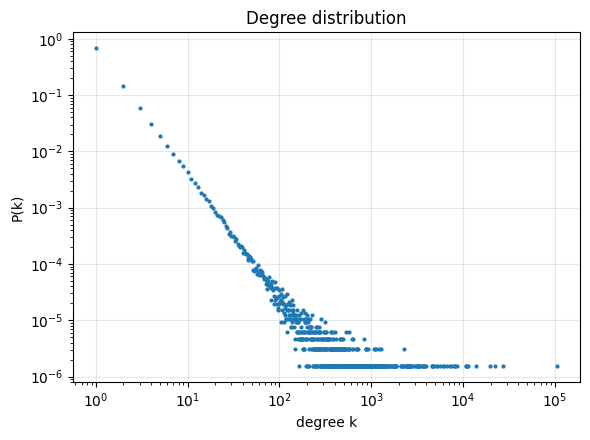

In [6]:
def pk(d):
    """P(degree = k) for k >= 1."""
    counts = np.bincount(d)
    k = np.nonzero(counts)[0]
    k = k[k > 0]
    return k, counts[k] / len(d)

fig, ax = plt.subplots(figsize=(6, 4.5))

k, p = pk(deg);   ax.loglog(k, p, '.', ms=4)

ax.set(xlabel='degree k', ylabel='P(k)', title='Degree distribution')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observations**

The network is very sparse and hub-dominated, where the maximum degree is more than 35,000 times the mean. The degree distribution is heavy-tailed, close to a straight line on the log-log plot.

### Task 1.3 Different layouts of the network

In [7]:
strength = np.array(g_und.strength(weights='weight'))               # retweets sent + received
el = np.array(g_und.get_edgelist())

# how big is the core for different thresholds? aim is around roughly 2,000-20,000 vertices
for t in (5, 10, 20, 50, 100, 200):
    keep = strength >= t
    print(f'strength >= {t:>3}: {keep.sum():>8,} vertices, {(keep[el[:,0]] & keep[el[:,1]]).sum():>9,} edges')

strength >=   5:   70,174 vertices,   475,478 edges
strength >=  10:   30,251 vertices,   303,247 edges
strength >=  20:   13,150 vertices,   179,351 edges
strength >=  50:    4,454 vertices,    76,591 edges
strength >= 100:    2,029 vertices,    33,001 edges
strength >= 200:      978 vertices,    11,131 edges


In [8]:
MIN_STRENGTH = 50                                                  
H = g_dir.induced_subgraph(np.where(strength >= MIN_STRENGTH)[0].tolist())
H = H.connected_components(mode='weak').giant()                    # drop small detached pieces
print(H.vcount(), 'vertices,', H.ecount(), 'edges')

H_dir = H # keep for 2.7
H_und = H_dir.as_undirected(mode="collapse", combine_edges={"weight": "sum"})
print(H_und.summary())

4213 vertices, 77316 edges
IGRAPH UNW- 4213 76584 -- 
+ attr: name (v), weight (e)


In [9]:
layout_names = ['random', 'circle', 'drl', 'lgl', 'fr']
if H_und.vcount() <= 3000:
    layout_names.append('kk')                                      # Kamada-Kawai is too slow for large graphs

layouts, times = {}, {}
for name in layout_names:
    random.seed(1)                                                 # same result on re-runs
    t0 = time.perf_counter()
    try:
        layouts[name] = H_und.layout(name)
    except Exception as e:
        print(name, 'failed:', e); continue
    times[name] = time.perf_counter() - t0
    print(f'{name:9s} {times[name]:7.1f} s')

random        0.0 s
circle        0.0 s
drl          35.0 s
lgl           7.6 s
fr            0.9 s


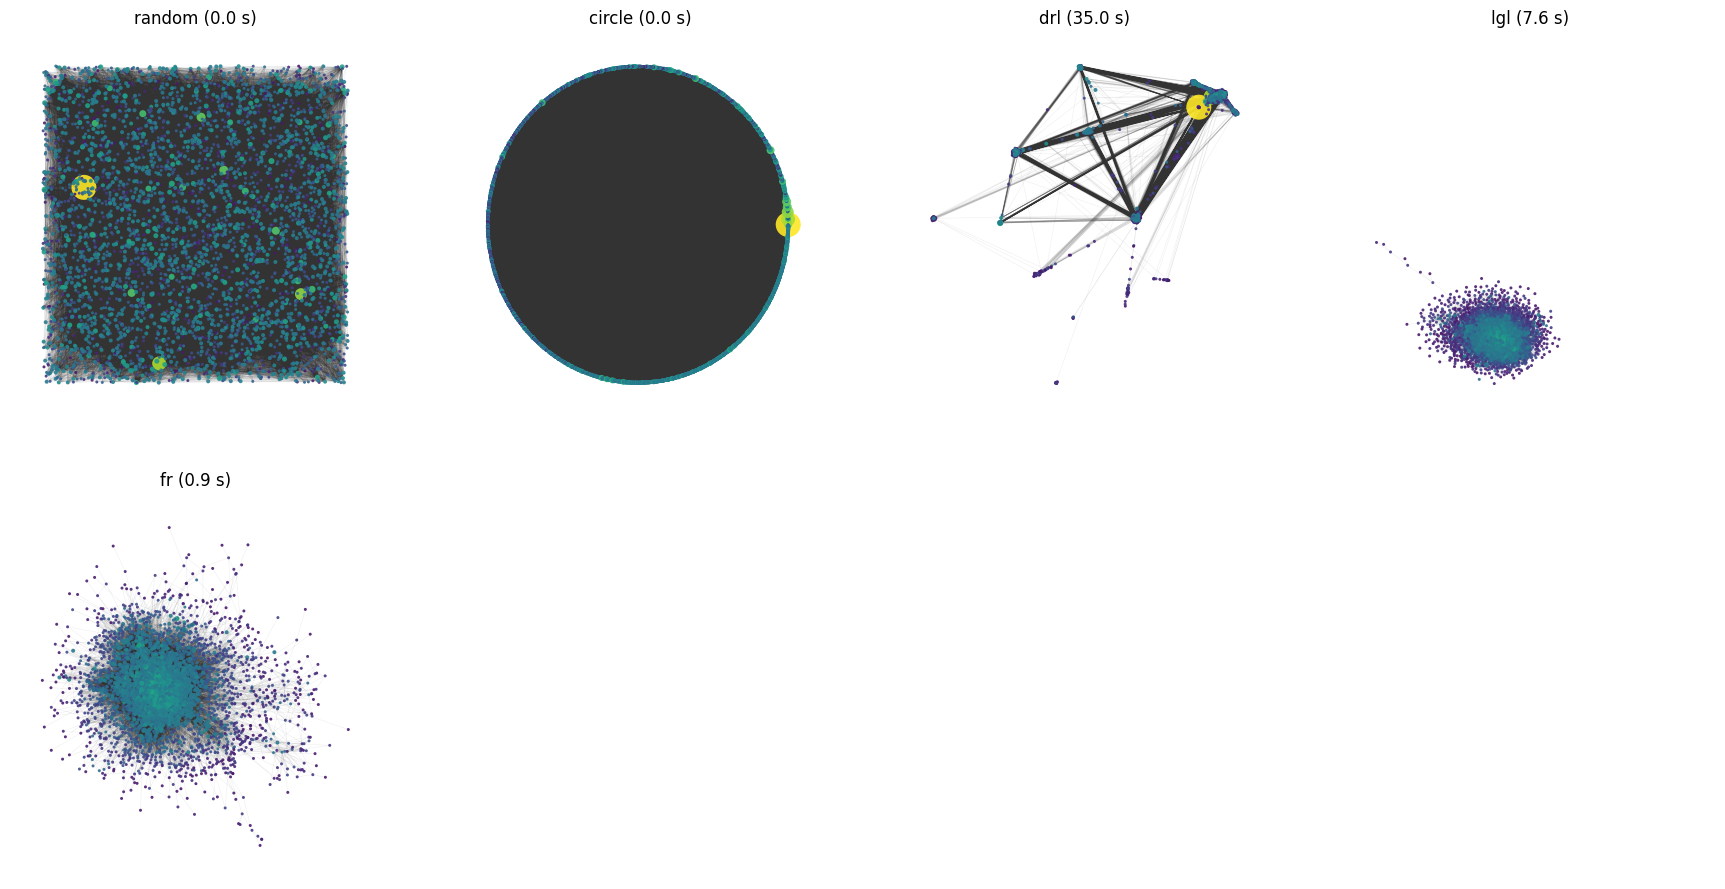

In [10]:
str_H = np.array(H_und.strength(weights='weight'))                    # retweets sent + received
size = 3 + 22 * np.sqrt(str_H / str_H.max())
shade = np.log1p(str_H) / np.log1p(str_H).max()
H_und.vs['color'] = [(*plt.cm.viridis(s)[:3], 0.9) for s in shade]    # bright = high strength (many retweets)
H_und.es['color'] = [(0.2, 0.2, 0.2, 0.08)] * H_und.ecount()              # very transparent edges

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for ax, name in zip(axes.ravel(), layouts):
    ig.plot(H_und, target=ax, layout=layouts[name], vertex_size=list(size),
            vertex_frame_width=0, vertex_label=None, edge_width=0.4)
    ax.set_title(f'{name} ({times[name]:.1f} s)')
for ax in axes.ravel()[len(layouts):]: ax.axis('off')
fig.savefig('layouts_compared.png', dpi=200, bbox_inches='tight')
plt.show()

**Observations**

The structure is hub-and-spoke, as the degree distribution suggested. Random and circle layouts only give the main hubs (in yellow), the rest is just a bunch of connections. DrL shows a few huge hubs with thick bundles of retweets from many low-degree accounts. FR and LGL show a dense core (many accounts that retweet and get retweeted) with a sparse periphery, plus a few distinct side clusters, probably separate communities or topics.

### Task 1.4 Retweet roles in the network

                actors
both              1773
retweeter only    1326
retweeted only    1114


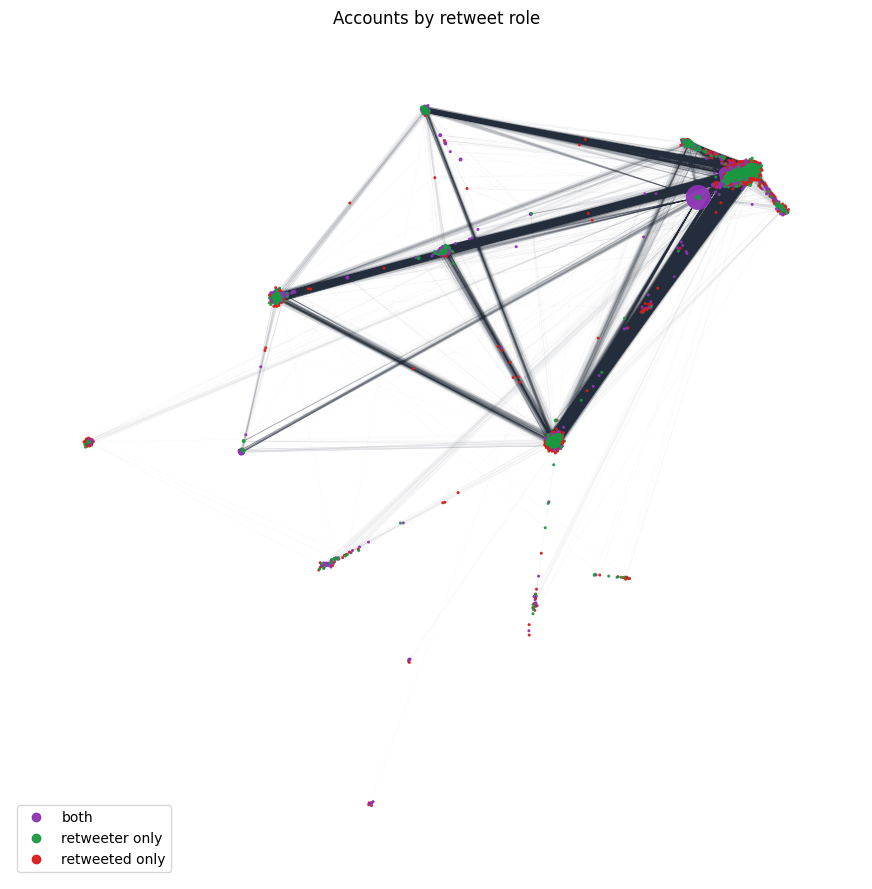

In [11]:
# account_groups.csv is not part of the supplied files; derive roles from retweet direction.
names = H_und.vs['name']
in_deg = np.asarray(H_dir.indegree())
out_deg = np.asarray(H_dir.outdegree())
role_values = np.select(
    [(in_deg > 0) & (out_deg > 0),
     (out_deg > 0) & (in_deg == 0),
     (in_deg > 0) & (out_deg == 0)],
    ['both', 'retweeter only', 'retweeted only'],
    default='no resolved ties',
)
role = pd.Series(role_values, index=H_dir.vs['name']).reindex(names).fillna('no resolved ties')
stance = role  # Task 2.5 reuses this category column.

stance_colors = {'both': (0.55, 0.20, 0.70, 0.95),
                 'retweeter only': (0.10, 0.60, 0.25, 0.95),
                 'retweeted only': (0.85, 0.10, 0.10, 0.95),
                 'no resolved ties': (0.65, 0.65, 0.65, 0.50)}

def plot_categories(categories, palette, layout_name, title, fname=None):
    categories = list(categories)
    fig, ax = plt.subplots(figsize=(11, 11))
    ig.plot(H_und, target=ax, layout=layouts[layout_name],
            vertex_color=[palette[c] for c in categories],
            vertex_size=list(size), vertex_frame_width=0, vertex_label=None,
            edge_color='rgba(35, 45, 60, 0.04)', edge_width=0.3)
    ax.set_title(title)
    ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=col, label=lab)
                       for lab, col in palette.items() if lab in set(categories)], loc='lower left')
    if fname: fig.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()

print(role.value_counts().to_frame('actors'))
plot_categories(role, stance_colors, 'drl', 'Accounts by retweet role', 'network_roles.png')

In [12]:
# how many accounts per category in this plot?
print(stance.value_counts().to_frame('accounts').assign(share=lambda d: (d['accounts'] / d['accounts'].sum()).round(3)))

# who is linked to whom, by category (weighted by number of retweets)
# the graph is undirected, so every edge is counted in both directions; rows = group of one end, columns = group of the other
src, dst = (list(x) for x in zip(*H_und.get_edgelist()))
a = np.concatenate([stance.iloc[src].values, stance.iloc[dst].values])
b = np.concatenate([stance.iloc[dst].values, stance.iloc[src].values])
w = np.concatenate([H_und.es['weight'], H_und.es['weight']])
mix = pd.crosstab(a, b, values=w, aggfunc='sum').fillna(0)
display(mix.div(mix.sum(axis=1), axis=0).round(3))

# Are actors with the same retweet role more likely to connect?
codes = pd.Categorical(stance).codes.tolist()
print('nominal assortativity by retweet role:', H_und.assortativity_nominal(codes, directed=False))

                accounts  share
both                1773  0.421
retweeter only      1326  0.315
retweeted only      1114  0.264


col_0,both,retweeted only,retweeter only
row_0,,,
both,0.425,0.059,0.516
retweeted only,0.258,0.000,0.742
retweeter only,0.752,0.248,0.000


nominal assortativity by retweet role: -0.29218910511232593


**Observations**

The groups are derived from the direction of known retweet ties: actors who retweet and are retweeted, actors who only retweet, and actors who are only retweeted. These describe network roles, not hashtag stance or personal beliefs. The category counts, weighted mixing table, and nominal assortativity are calculated from the filtered core above.

# PART 2: Micro-level Analysis

### Task 2.1 Degrees of the nodes

[[105573, '1006419421244678144'], [27243, '813286'], [22238, '878247600096509952']]


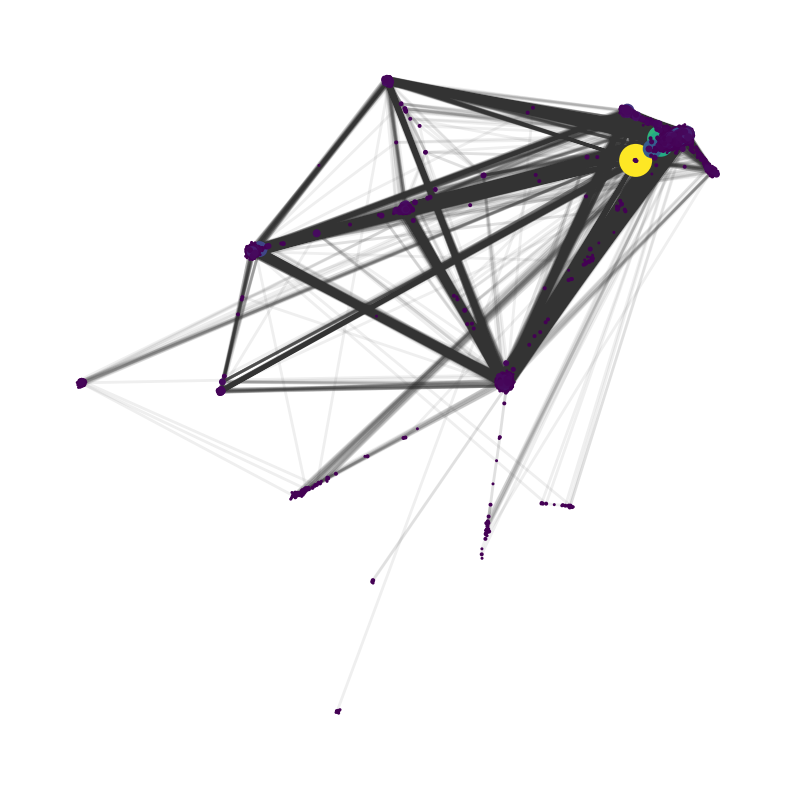

In [13]:
# Top-3 on the full (undirected) simplified graph
G = g_und
deg_G = G.degree()
act = G.vs["name"]
degrees = [ [ deg_G[i], act[i] ] for i in range(len(deg_G)) ]
degrees.sort(reverse = True)
print(degrees[0:3])

# Plot on the reduced graph that the layouts were computed on
deg_H = H_und.degree()
max_d = max(deg_H)

# Vertex size proportional to degree (sqrt so that the small nodes stay visible)
size_deg = [ 3 + 30 * (d / max_d) ** 0.5 for d in deg_H ]
# Vertex colour from degree
cmap = plt.get_cmap("viridis")
color_deg = [ cmap(d / max_d) for d in deg_H ]

fig, ax = plt.subplots(figsize=(10, 10))
ig.plot(H_und, target=ax, layout=layouts["drl"], vertex_size=size_deg,
        vertex_color=color_deg, vertex_label="", vertex_frame_width=0)
plt.show()

### Task 2.2 Betweenness functionality implementation

In [14]:
def calc_betweenness(graph, k):
  n = graph.vcount()
  nodes = list(range(n))
  seed = random.Random(42)
  source = seed.sample(nodes, k)
  target = seed.sample(nodes, k)

  paths = []
  
  for start in source:
    for end in target:
      if start != end:
        paths.append(graph.get_shortest_path(start, to=end, output = "vpath"))

  node_on_path = [0] * graph.vcount()
  for path in paths:
    for node in path[1: -1]:
      node_on_path[node] += 1

  scale = n * (n - 1) / (2 * len(paths))
  return [v * scale for v in node_on_path]

In [ ]:
er = ig.Graph.Erdos_Renyi(n=H_und.vcount(), m=H_und.ecount(), directed=False)
k = 1000

exact_H = H_und.betweenness(directed = False)
exact_er = er.betweenness(directed = False)
approx_H = calc_betweenness(H_und, k)
approx_er = calc_betweenness(er, k)

print(spearmanr(approx_H, exact_H).correlation)
print(spearmanr(approx_er, exact_er).correlation)

top = 20
top_exact  = np.argsort(exact_H)[::-1][:top]     # vertex IDs, highest betweenness first
top_approx = np.argsort(approx_H)[::-1][:top]

print("overlap (ours and igraph on network H) in top", top, ":", len(set(top_exact) & set(top_approx)))

for rank, (e, a) in enumerate(zip(top_exact, top_approx), 1):
    print(rank, "| exact:", H_und.vs[e]["name"], round(exact_H[e]),
                "| approx:", H_und.vs[a]["name"], round(approx_H[a]))

***Observations***

Our function of betweenness takes a sample from the nodes and calculates the betweenness on them. Therefore for smaller smaple size (k) values, the betweenness measures differ more. The more nodes are sampled the higher the overlap of betweenness measures climbs (0.49 → 0.62 → 0.67 → 0.75 on H, and 0.28 → 0.37 → 0.45 → 0.52 on ER for k = 200, 400, 600, 1000). However they climb more for the H network than for the random ER one. It can also be seen that the nodes with the highest betweenness align between our implementation and the iGraph one. The validation on the ER network performs worse because the betweenness will be similar for all the nodes, therefore there is little ranking to recover and the sampling will not highlight that as well.

### Task 2.3 Top 10 actors for degree and betweenness

--- Retweet network (core) ---
Top degree:      [('1006419421244678144', 2085), ('15088481', 1359), ('14266598', 1270), ('3459051', 875), ('2518143973', 750), ('21786618', 607), ('811229675758505984', 569), ('159955958', 555), ('14159148', 553), ('1075123146641039363', 549)]
Top betweenness: [('1006419421244678144', 2394957), ('1174664712291794944', 931620), ('15088481', 683101), ('14266598', 593622), ('3459051', 272065), ('14159148', 207668), ('2518143973', 187572), ('811229675758505984', 148798), ('21786618', 124672), ('2712674750', 117503)]
overlap: 8 of 10
--- ER graph ---
Top degree:      [(2882, 58), (2876, 56), (882, 56), (2955, 56), (1464, 56), (2925, 56), (1283, 55), (3921, 55), (615, 54), (1812, 54)]
Top betweenness: [(2882, 8903), (2876, 8364), (2955, 8356), (882, 8316), (3921, 8302), (2925, 8296), (1464, 8276), (1283, 8016), (1812, 7779), (3601, 7705)]
overlap: 9 of 10


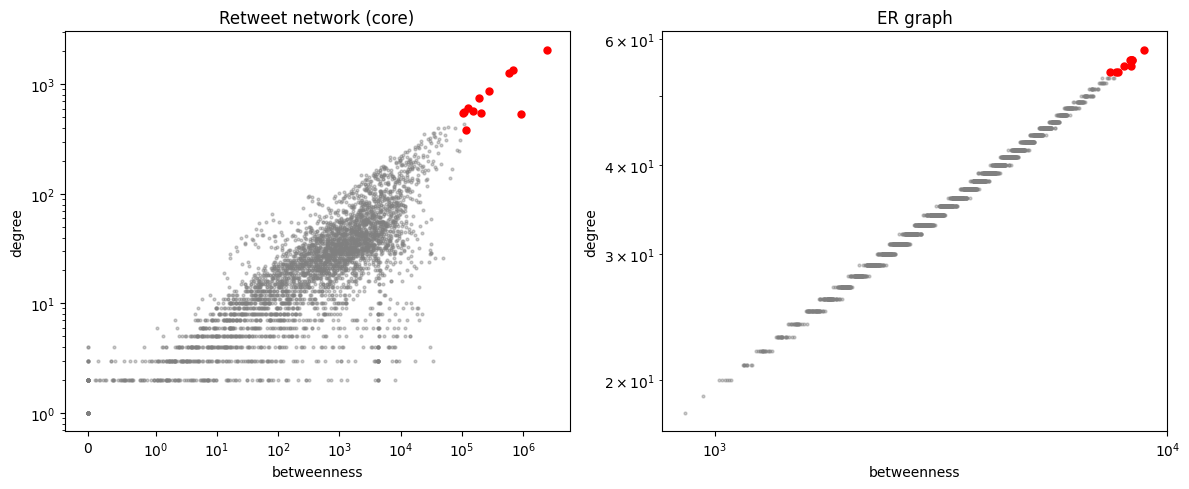

In [ ]:
def top_and_plot(graph, bet, title, ax, top=10):
    deg = np.array(graph.degree())
    bet = np.array(bet)
    ids = graph.vs["name"] if "name" in graph.vs.attributes() else list(range(graph.vcount()))

    top_deg = np.argsort(deg)[::-1][:top]
    top_bet = np.argsort(bet)[::-1][:top]

    print(f"--- {title} ---")
    print("Top degree:     ", [(ids[i], int(deg[i])) for i in top_deg])
    print("Top betweenness:", [(ids[i], int(bet[i])) for i in top_bet])
    print("overlap:", len(set(top_deg) & set(top_bet)), "of", top)

    ax.scatter(bet, deg, s=4, alpha=0.4, color="grey")
    both = list(set(top_deg) | set(top_bet))                 # highlight the top-10 of either measure
    ax.scatter(bet[both], deg[both], s=25, color="red")
    ax.set_xscale("symlog", linthresh=1)                     # symlog because many nodes have betweenness 0
    ax.set_yscale("log")
    ax.set_xlabel("betweenness"); ax.set_ylabel("degree"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_and_plot(H_und, exact_H,  "Retweet network (core)", axes[0])      # exact values from 2.2
top_and_plot(er,    exact_er, "ER graph", axes[1])
plt.tight_layout()
plt.savefig("betweenness_vs_degree.png", dpi=150)
plt.show()

***Observations***

9 out of 10 highest degree and highest betweenness actors overlap for both the ER and the H network. Therefore they are mostly complementary with some outliers.

Betweenness and degree are positively related, with the hubs in the top right, as expected. For a given degree, betweenness varies by orders of magnitude, and accounts far to the right of their degree are brokers that connect otherwise separate groups, which degree alone does not reveal. Many accounts with degree > 0 have betweenness 0 (they only retweet or are only retweeted). The ER graph shows a tight cloud with no outliers.

### Task 2.4 Missing description of the task ://

### Task 2.5 Top-k actors

In [ ]:
K = 5
df = pd.DataFrame({"account_id": H_und.vs["name"],
                   "stance": stance.values,
                   "degree": np.array(H_und.degree()),
                   "betweenness": np.array(exact_H)})
df["deg_rank_overall"] = df["degree"].rank(ascending=False, method="min").astype(int)
df["bet_rank_overall"] = df["betweenness"].rank(ascending=False, method="min").astype(int)

def topk(measure, k=K):
    return (df.sort_values(measure, ascending=False).groupby("stance").head(k)
              .sort_values(["stance", measure], ascending=[True, False])
              [["stance", "account_id", "degree", "betweenness", "deg_rank_overall", "bet_rank_overall"]]
              .reset_index(drop=True))

print(f"Top-{K} by degree within each stance group"); display(topk("degree"))
print(f"Top-{K} by betweenness within each stance group"); display(topk("betweenness"))

Top-5 by degree within each stance group


,stance,account_id,degree,betweenness,deg_rank_overall,bet_rank_overall
0,both,1006419421244678144,2085,2.394957e+06,1,1
1,both,15088481,1359,6.831014e+05,2,3
2,both,14266598,1270,5.936227e+05,3,4
3,both,3459051,875,2.720651e+05,4,5
4,both,2518143973,750,1.875726e+05,5,7
5,retweeted only,21786618,607,1.246728e+05,6,9
6,retweeted only,811229675758505984,569,1.487982e+05,7,8
7,retweeted only,1080930414280298499,402,4.126683e+04,14,29
8,retweeted only,25341283,400,5.091239e+04,16,23
9,retweeted only,813286,345,5.208275e+04,22,22


Top-5 by betweenness within each stance group


,stance,account_id,degree,betweenness,deg_rank_overall,bet_rank_overall
0,both,1006419421244678144,2085,2.394957e+06,1,1
1,both,15088481,1359,6.831014e+05,2,3
2,both,14266598,1270,5.936227e+05,3,4
3,both,3459051,875,2.720651e+05,4,5
4,both,14159148,553,2.076685e+05,9,6
5,retweeted only,811229675758505984,569,1.487982e+05,7,8
6,retweeted only,21786618,607,1.246728e+05,6,9
7,retweeted only,813286,345,5.208275e+04,22,22
8,retweeted only,25341283,400,5.091239e+04,16,23
9,retweeted only,878247600096509952,26,4.824253e+04,1845,24


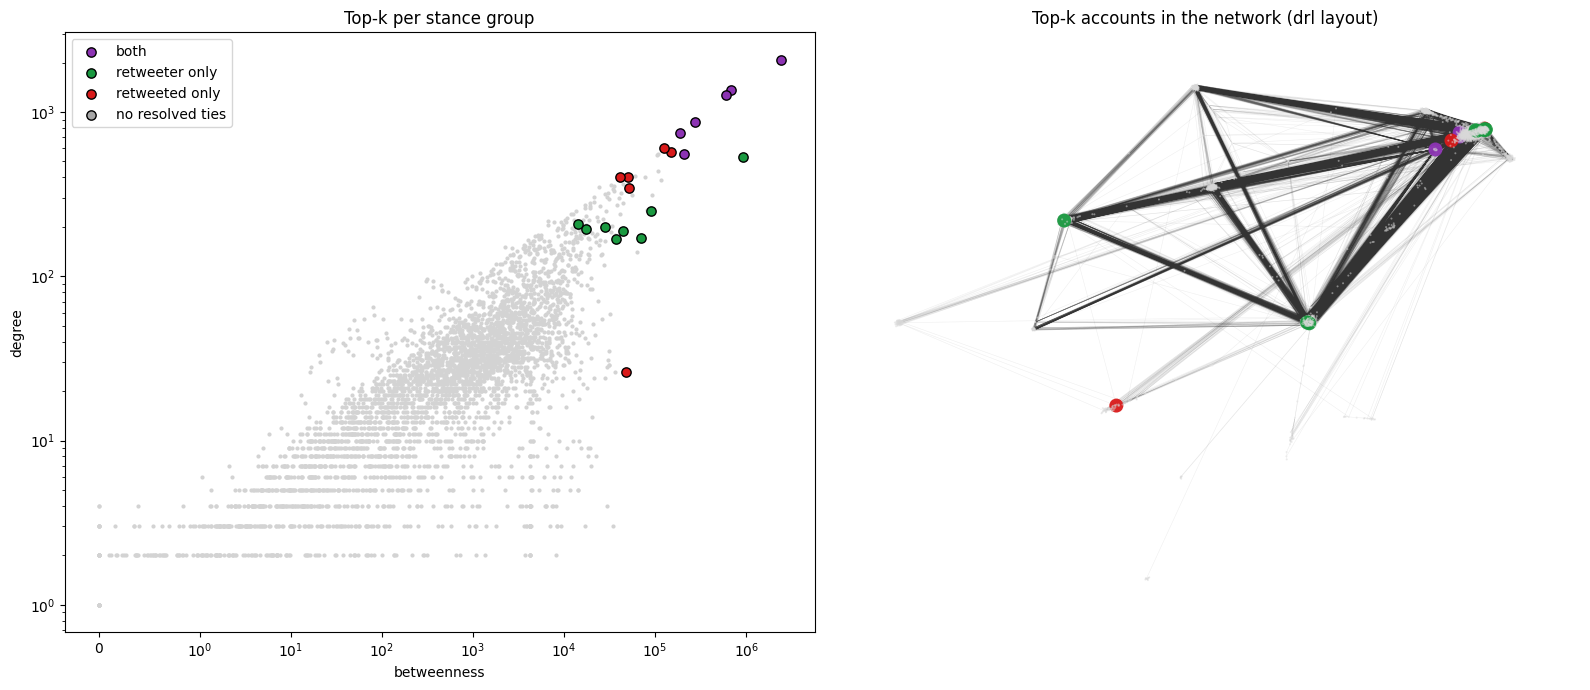

In [ ]:
sel = sorted(set(topk("degree").merge(df.reset_index(), on="account_id")["index"]) |
             set(topk("betweenness").merge(df.reset_index(), on="account_id")["index"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# (a) betweenness vs degree scatter, top-k accounts highlighted
ax = axes[0]
ax.scatter(df["betweenness"], df["degree"], s=4, color="lightgrey")
for lab, col in stance_colors.items():
    m = df.loc[sel][df.loc[sel, "stance"] == lab]
    ax.scatter(m["betweenness"], m["degree"], s=45, color=col[:3], edgecolor="black", label=lab)
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("log")
ax.set_xlabel("betweenness"); ax.set_ylabel("degree"); ax.legend(); ax.set_title("Top-k per stance group")

# (b) the same accounts in the node-link plot
vcol  = [(0.85, 0.85, 0.85, 0.5)] * H_und.vcount()
vsize = [2] * H_und.vcount()
for i in sel:
    vcol[i] = stance_colors[df.loc[i, "stance"]]; vsize[i] = 14
ig.plot(H_und, target=axes[1], layout=layouts["drl"], vertex_color=vcol, vertex_size=vsize,
        vertex_frame_width=0, vertex_label=None, edge_width=0.4)
axes[1].set_title("Top-k accounts in the network (drl layout)")
plt.tight_layout(); plt.savefig("topk_by_stance.png", dpi=150); plt.show()

***Observations***

The tables rank actors within each observed retweet role. Degree favors actors with many direct neighbors, while betweenness can elevate actors that connect otherwise separate parts of the core. Group rankings depend on the role definition and on the strength-filtered core; they do not establish credibility, intent, or causal influence.

### Task 2.6 Actors with low/high clustering coefficient

accounts with degree >= 5: 3,529 of 4,213
count    3529.000
mean        0.115
std         0.109
min         0.000
5%          0.000
10%         0.016
25%         0.044
50%         0.084
75%         0.153
90%         0.250
95%         0.324
max         0.933
dtype: float64
average clustering: core = 0.115, ER = 0.009
low (C <= 0.016): 353 accounts | high (C >= 0.250): 366 accounts


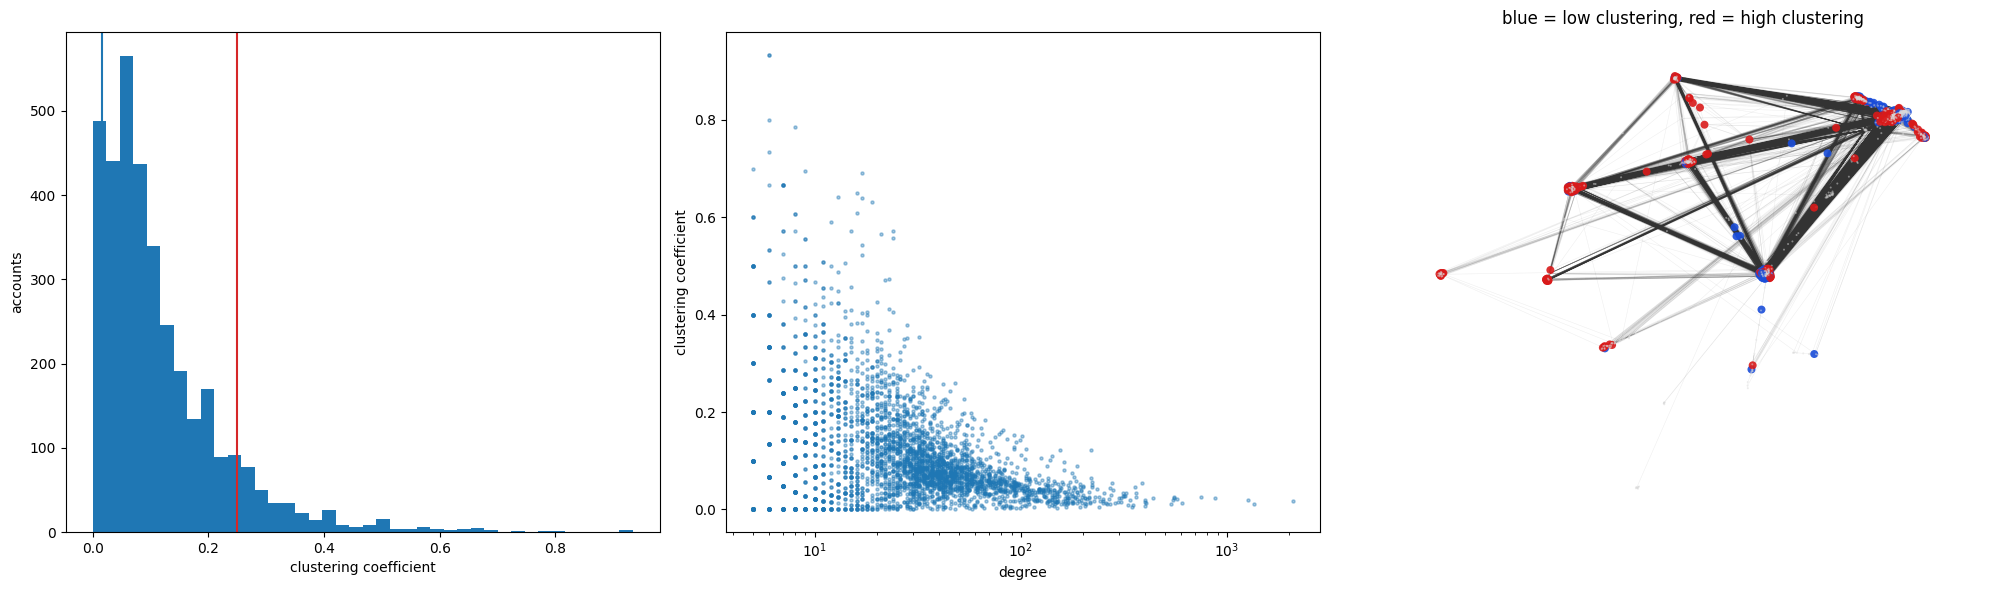

,account_id,degree,clustering
1855,3873984133,5,0.0
754,21733692,15,0.0
224,16583846,8,0.0
1739,4806260786,8,0.0
1735,755835576,5,0.0
1725,217183011,5,0.0
1719,14618896,5,0.0
236,146820325,8,0.0


,account_id,degree,clustering
1942,2504642767,17,0.691176
2745,205546805,9,0.694444
2560,135857034,5,0.700000
2730,17969699,6,0.733333
1540,710241948171304960,8,0.785714
2986,17053937,6,0.800000
1261,1163391687516991488,6,0.933333
1263,295783331,6,0.933333


In [ ]:
C = np.array(H_und.transitivity_local_undirected(mode="nan"))     # NaN where degree < 2
d = np.array(H_und.degree())
MIN_DEG = 5
ok = (d >= MIN_DEG) & ~np.isnan(C)
print(f"accounts with degree >= {MIN_DEG}: {ok.sum():,} of {len(d):,}")
print(pd.Series(C[ok]).describe(percentiles=[.05, .1, .25, .5, .75, .9, .95]).round(3))

# baseline: the random ER graph from Task 2.2
C_er = np.array(er.transitivity_local_undirected(mode="nan")); d_er = np.array(er.degree())
ok_er = (d_er >= MIN_DEG) & ~np.isnan(C_er)
print(f"average clustering: core = {C[ok].mean():.3f}, ER = {C_er[ok_er].mean():.3f}")

LOW, HIGH = np.quantile(C[ok], 0.10), np.quantile(C[ok], 0.90)
low  = ok & (C <= LOW)
high = ok & (C >= HIGH)
print(f"low (C <= {LOW:.3f}): {low.sum()} accounts | high (C >= {HIGH:.3f}): {high.sum()} accounts")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].hist(C[ok], bins=40); axes[0].set_xlabel("clustering coefficient"); axes[0].set_ylabel("accounts")
axes[0].axvline(LOW, color="tab:blue"); axes[0].axvline(HIGH, color="tab:red")

axes[1].scatter(d[ok], C[ok], s=5, alpha=0.4); axes[1].set_xscale("log")
axes[1].set_xlabel("degree"); axes[1].set_ylabel("clustering coefficient")

vcol  = [(0.85, 0.85, 0.85, 0.5)] * H_und.vcount()
vsize = [2] * H_und.vcount()
for i in np.where(low)[0]:  vcol[i], vsize[i] = (0.1, 0.3, 0.85, 0.9), 8      # blue = low
for i in np.where(high)[0]: vcol[i], vsize[i] = (0.85, 0.1, 0.1, 0.9), 8      # red = high
ig.plot(H_und, target=axes[2], layout=layouts["drl"], vertex_color=vcol, vertex_size=vsize,
        vertex_frame_width=0, vertex_label=None, edge_width=0.4)
axes[2].set_title("blue = low clustering, red = high clustering")
plt.tight_layout(); plt.savefig("clustering.png", dpi=150); plt.show()

# who are they?
t = pd.DataFrame({"account_id": H_und.vs["name"], "degree": d, "clustering": C})[ok]
display(t.sort_values("clustering").head(8)); display(t.sort_values("clustering").tail(8))

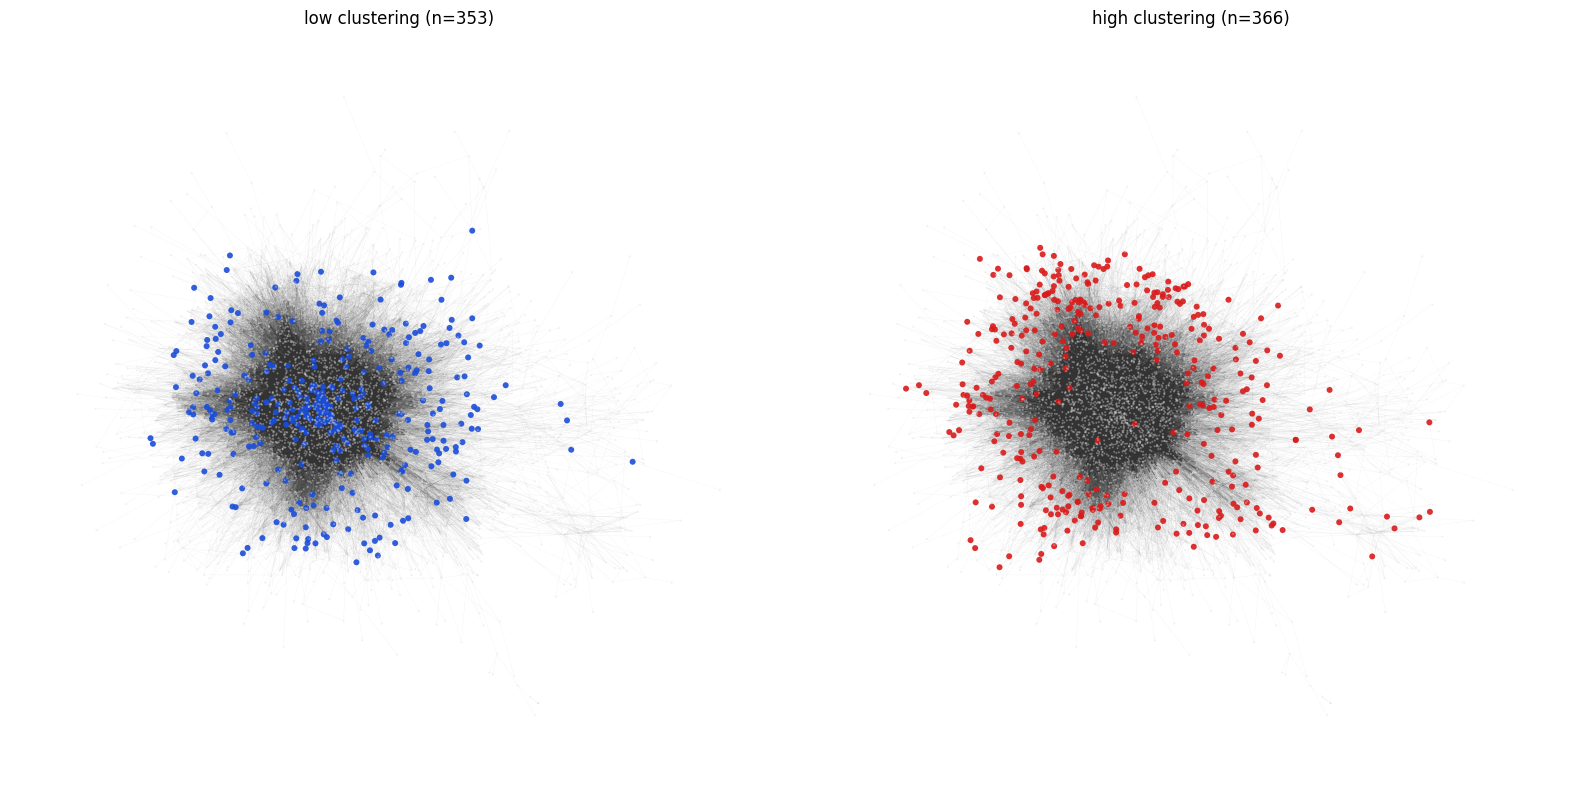

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, mask, col, title in [(axes[0], low,  (0.1, 0.3, 0.85, 0.9), "low clustering"),
                             (axes[1], high, (0.85, 0.1, 0.1, 0.9), "high clustering")]:
    vcol  = [(0.85, 0.85, 0.85, 0.4)] * H_und.vcount()
    vsize = [2] * H_und.vcount()
    for i in np.where(mask)[0]:
        vcol[i], vsize[i] = col, 6
    ig.plot(H_und, target=ax, layout=layouts["fr"], vertex_color=vcol, vertex_size=vsize,
            vertex_frame_width=0, vertex_label=None, edge_width=0.2)
    ax.set_title(f"{title} (n={mask.sum()})")
plt.tight_layout(); plt.show()

***Observations***

First, looking at accounts with very low degrees is not useful as its either undefined or it can only take a few values. So, the 10% of the top and bottom were not used. 

In general, clustering is really low and it falls as degree increases. The accounts with the highest degree all have coefs close to 0. These are hubs whose followers do not retweet each other (hub-and-spoke pattern). The highest coef values only appear at small degrees (5 t 12). So, only small groups of accounts retweet each others.

Low clustering accounts are mainly in the centre and high-clustering accounts more in the outskirts. This makes sense, the hubs are in the centre whose neigours rarely retweet each other, and on the outskirts are small but tight groups.

### Task 2.7 Strength, hub and authority scores directed and weighted

In [ ]:
deg_und = np.array(H_und.degree())
deg_in  = np.array(H_dir.indegree());  deg_out = np.array(H_dir.outdegree())
str_in  = np.array(H_dir.strength(mode="in",  weights="weight"))     # retweets received
str_out = np.array(H_dir.strength(mode="out", weights="weight"))     # retweets sent
auth = np.array(H_dir.authority_score(weights="weight"))             # scaled so the maximum is 1
hub  = np.array(H_dir.hub_score(weights="weight"))

res = pd.DataFrame({"account_id": H_dir.vs["name"], "degree": deg_und, "in_deg": deg_in, "out_deg": deg_out,
                    "strength": str_in + str_out, "in_str": str_in, "out_str": str_out,
                    "authority": auth, "hub": hub})
res["deg_rank"] = res["degree"].rank(ascending=False, method="min").astype(int)

for a, b in [("degree", "strength"), ("in_deg", "authority"), ("out_deg", "hub"), ("in_str", "authority"), ("out_str", "hub")]:
    print(f"Spearman {a} vs {b}: {spearmanr(res[a], res[b]).correlation:.2f}")

for col in ["strength", "authority", "hub"]:
    print(f"\nTop 10 by {col}")
    display(res.sort_values(col, ascending=False).head(10).round(3))

Spearman degree vs strength: 0.95
Spearman in_deg vs authority: 0.97
Spearman out_deg vs hub: 0.94
Spearman in_str vs authority: 0.97
Spearman out_str vs hub: 0.95

Top 10 by strength


C:\Users\DELL\AppData\Local\Temp\ipykernel_23264\693013181.py:5: RuntimeWarning: More than 30% of hub or authority scores are zeros. The presence of zero values indicates that the solution is not unique, thus the returned result may not be meaningful. Location: src/centrality/hub_authority.c:81
  auth = np.array(H_dir.authority_score(weights="weight"))             # scaled so the maximum is 1
C:\Users\DELL\AppData\Local\Temp\ipykernel_23264\693013181.py:6: RuntimeWarning: More than 30% of hub or authority scores are zeros. The presence of zero values indicates that the solution is not unique, thus the returned result may not be meaningful. Location: src/centrality/hub_authority.c:81
  hub  = np.array(H_dir.hub_score(weights="weight"))


,account_id,degree,in_deg,out_deg,strength,in_str,out_str,authority,hub,deg_rank
0,1006419421244678144,2085,1984,144,24673.0,24506.0,167.0,1.000,0.038,1
23,15088481,1359,1358,2,7087.0,7084.0,3.0,0.220,0.000,2
53,14266598,1270,1198,104,4532.0,4311.0,221.0,0.127,0.134,3
97,3459051,875,831,58,2186.0,2109.0,77.0,0.065,0.036,4
75,2518143973,750,711,50,2029.0,1964.0,65.0,0.075,0.038,5
328,21786618,607,607,0,1527.0,1527.0,0.0,0.035,-0.000,6
2,14159148,553,544,17,1513.0,1477.0,36.0,0.026,0.003,9
789,950477244,332,332,0,1211.0,1211.0,0.0,0.029,-0.000,24
185,811229675758505984,569,569,0,1041.0,1041.0,0.0,0.023,-0.000,7
10,159955958,555,539,21,983.0,961.0,22.0,0.034,0.027,8



Top 10 by authority


,account_id,degree,in_deg,out_deg,strength,in_str,out_str,authority,hub,deg_rank
0,1006419421244678144,2085,1984,144,24673.0,24506.0,167.0,1.000,0.038,1
23,15088481,1359,1358,2,7087.0,7084.0,3.0,0.220,0.000,2
53,14266598,1270,1198,104,4532.0,4311.0,221.0,0.127,0.134,3
75,2518143973,750,711,50,2029.0,1964.0,65.0,0.075,0.038,5
97,3459051,875,831,58,2186.0,2109.0,77.0,0.065,0.036,4
328,21786618,607,607,0,1527.0,1527.0,0.0,0.035,-0.000,6
10,159955958,555,539,21,983.0,961.0,22.0,0.034,0.027,8
789,950477244,332,332,0,1211.0,1211.0,0.0,0.029,-0.000,24
2,14159148,553,544,17,1513.0,1477.0,36.0,0.026,0.003,9
111,1075123146641039363,549,546,5,858.0,853.0,5.0,0.025,0.002,10



Top 10 by hub


,account_id,degree,in_deg,out_deg,strength,in_str,out_str,authority,hub,deg_rank
1517,2712674750,385,103,288,859.0,324.0,535.0,0.01,1.000,17
3045,1174664712291794944,535,0,535,805.0,0.0,805.0,0.00,0.983,11
3495,250548583,186,0,186,325.0,0.0,325.0,0.00,0.982,85
3412,227089726,150,0,150,280.0,0.0,280.0,0.00,0.970,137
3051,115902452,154,0,154,281.0,0.0,281.0,0.00,0.956,131
3565,2781732464,208,0,208,348.0,0.0,348.0,0.00,0.938,63
1794,1014522329114783745,233,16,220,391.0,18.0,373.0,0.00,0.937,50
3843,4845265193,123,0,123,220.0,0.0,220.0,0.00,0.932,203
163,1000271956288180229,19,0,19,105.0,0.0,105.0,0.00,0.932,2307
3629,3018326793,125,0,125,219.0,0.0,219.0,0.00,0.894,199


In [ ]:
print("authority = 0:", (auth == 0).sum(), "| of those with in-degree > 0:", ((auth == 0) & (deg_in > 0)).sum())
print("hub = 0:      ", (hub == 0).sum(),  "| of those with out-degree > 0:", ((hub == 0) & (deg_out > 0)).sum())

auth_u = np.array(H_dir.authority_score(weights=None))     # unweighted version for comparison
hub_u  = np.array(H_dir.hub_score(weights=None))
print("zeros unweighted:", (auth_u == 0).sum(), (hub_u == 0).sum())
print("Spearman weighted vs unweighted - authority:", round(spearmanr(auth, auth_u).correlation, 2),
      "| hub:", round(spearmanr(hub, hub_u).correlation, 2))

C:\Users\DELL\AppData\Local\Temp\ipykernel_23264\4134981528.py:4: RuntimeWarning: More than 30% of hub or authority scores are zeros. The presence of zero values indicates that the solution is not unique, thus the returned result may not be meaningful. Location: src/centrality/hub_authority.c:81
  auth_u = np.array(H_dir.authority_score(weights=None))     # unweighted version for comparison


authority = 0: 1326 | of those with in-degree > 0: 0
hub = 0:       1115 | of those with out-degree > 0: 1
zeros unweighted: 1340 1125
Spearman weighted vs unweighted - authority: 0.99 | hub: 0.97


C:\Users\DELL\AppData\Local\Temp\ipykernel_23264\4134981528.py:5: RuntimeWarning: More than 30% of hub or authority scores are zeros. The presence of zero values indicates that the solution is not unique, thus the returned result may not be meaningful. Location: src/centrality/hub_authority.c:81
  hub_u  = np.array(H_dir.hub_score(weights=None))


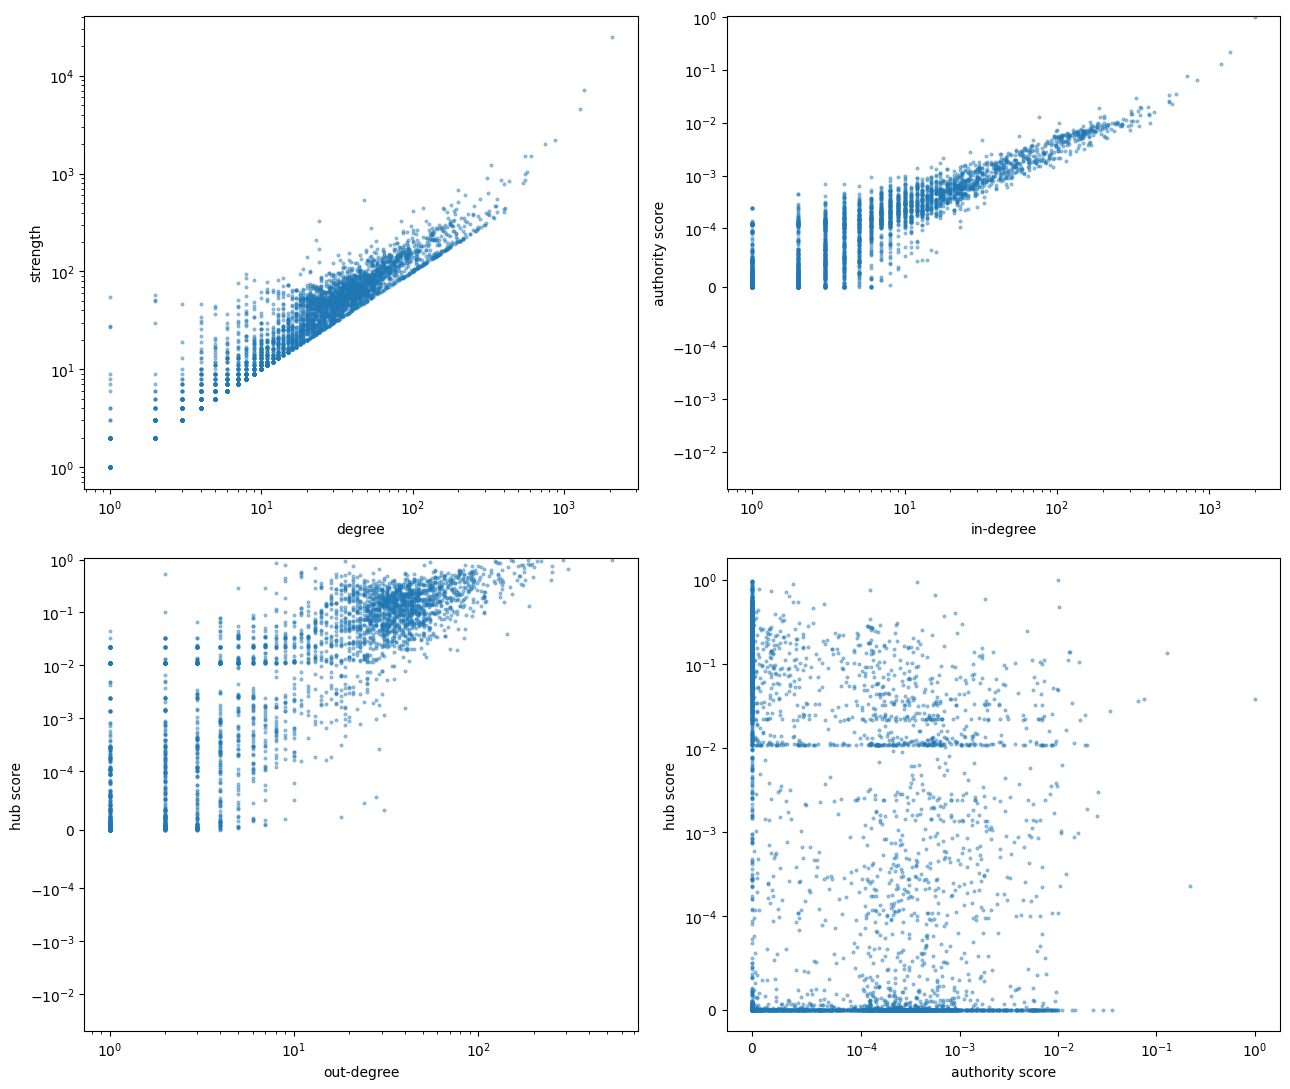

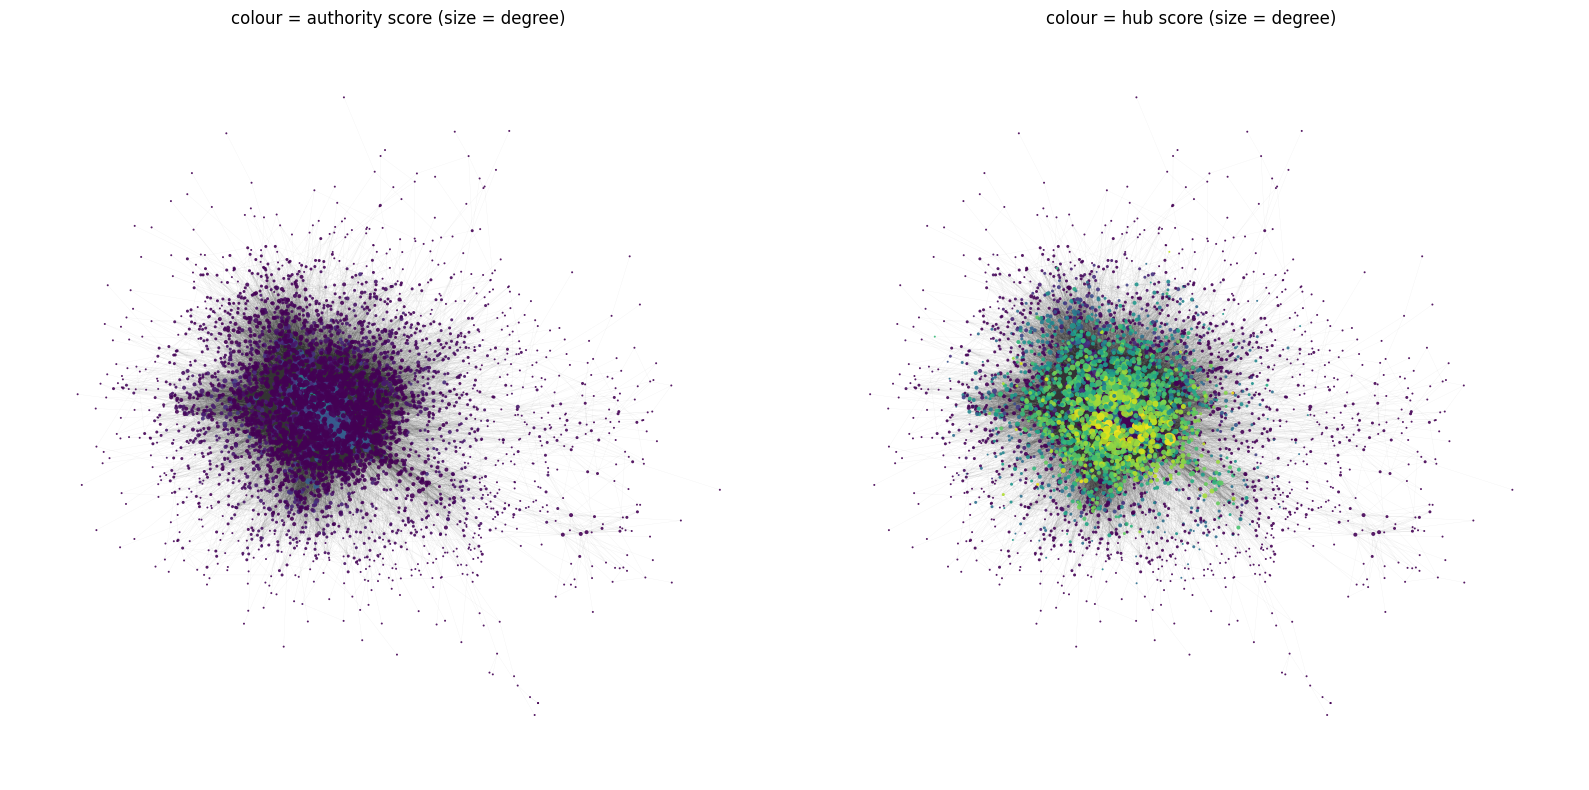

In [ ]:
# 1) scatter plots: weights and direction versus plain degree
fig, axes_sc = plt.subplots(2, 2, figsize=(13, 11))

axes_sc[0, 0].scatter(deg_und, str_in + str_out, s=4, alpha=0.4)
axes_sc[0, 0].set(xscale="log", yscale="log", xlabel="degree", ylabel="strength")

axes_sc[0, 1].scatter(deg_in, auth, s=4, alpha=0.4)
axes_sc[0, 1].set(xscale="log", xlabel="in-degree", ylabel="authority score")
axes_sc[0, 1].set_yscale("symlog", linthresh=1e-4)

axes_sc[1, 0].scatter(deg_out, hub, s=4, alpha=0.4)
axes_sc[1, 0].set(xscale="log", xlabel="out-degree", ylabel="hub score")
axes_sc[1, 0].set_yscale("symlog", linthresh=1e-4)

axes_sc[1, 1].scatter(auth, hub, s=4, alpha=0.4)
axes_sc[1, 1].set(xlabel="authority score", ylabel="hub score")
axes_sc[1, 1].set_xscale("symlog", linthresh=1e-4)
axes_sc[1, 1].set_yscale("symlog", linthresh=1e-4)

plt.tight_layout(); plt.show()

# 2) node-link plots: size = degree, colour = authority / hub score (log-compressed)
sizes = 2 + 22 * np.sqrt(deg_und / deg_und.max())
fig, axes_nl = plt.subplots(1, 2, figsize=(16, 8))
for ax, score, title in [(axes_nl[0], auth, "colour = authority score"),
                         (axes_nl[1], hub,  "colour = hub score")]:
    score = np.clip(score, 0, None)                      # remove tiny negative values (numerical noise)
    shade = np.log1p(1000 * score) / np.log1p(1000)
    ig.plot(H_und, target=ax, layout=layouts["fr"], vertex_size=list(sizes),
            vertex_color=[(*plt.cm.viridis(s)[:3], 0.9) for s in shade],
            vertex_frame_width=0, vertex_label=None, edge_width=0.2)
    ax.set_title(title + " (size = degree)")
plt.tight_layout(); plt.show()

***Observations***

 - Authority score is high for accounts that are retweeted by accounts that themselves retweet many good sources. It rewards being retweeted, and by the right accounts.

 - Hub score is the mirror image: high for accounts that retweet many good authorities. These are curators or amplifiers.

The strength is similar to the degree ranking. However, degree treats a person that has retweeded once and multiple times the same, but strength separates them. For example, Account 950477244 moves from degree rank 35 to 9th by strength. A few accounts with only 1 to 3 connections have strength of 50 to 100, for instance, because they retweeted the same accounts many times

Authority grows with in-degree and has a lot of variation when in-degree is low. Hub score increases with out-degree, and for low out-degree it varies a lot depending on whom the account retweets. Roles are separated and clear at the extremes where top authorities have low hub scores and top hubs have authority 0.

Ignoring direction and weights does hide things. First, direction shows that accounts are either retweeted or retweeting, and almost never both. If he have no direction, these 2 are mixed. Then, weights show repeated retweeting. 

The scores are computed only in the core and are relative (maximum 1). igraph warned that over 30% of the scores are zero. Almost all are structural (accounts that were never retweeted or never retweeting), and weighted and unweighted scores correlate at 0.99 (authority) and 0.96 (hub). 

# Part 3: Processes on networks

### Task 3.1 Netowrks largest component

Connected components in retweet network: 9,721
Largest component: 631,488 vertices
Order: 631,488 | Size: 1,214,006
Connected: True | Density: 6.08865e-06
Isolates in largest component: 0


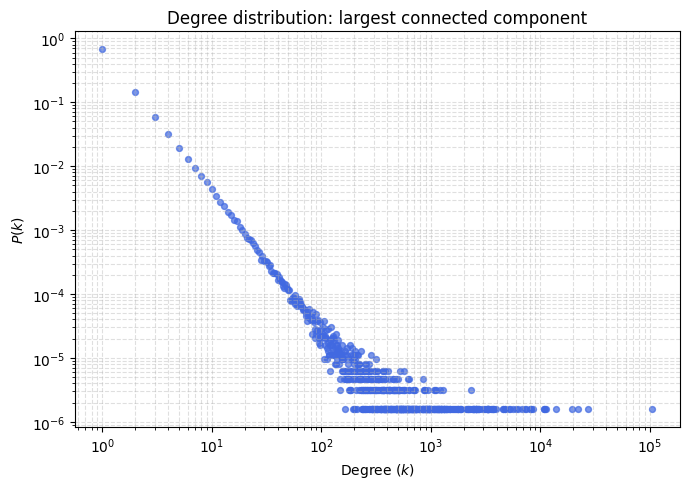

In [16]:
# Find all connected components of the unweighted, undirected network,
# then copy the largest one into a separate graph for the simulations.
from pathlib import Path
import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Reuse the graph if earlier setup cells ran; otherwise build it from the supplied CSV.
if 'g_und' in globals():
    task3_network = g_und
elif 'g' in globals():
    if g.is_directed():
        combine = {'weight': 'sum'} if 'weight' in g.es.attributes() else None
        task3_network = g.as_undirected(mode='collapse', combine_edges=combine)
    else:
        task3_network = g
else:
    data_candidates = [Path('data/network_data'), Path('../data/network_data')]
    data_dir = next((path for path in data_candidates if (path / 'edges.csv').exists()), None)
    if data_dir is None:
        raise FileNotFoundError('Could not find data/network_data/edges.csv')
    edge_data = pd.read_csv(
        data_dir / 'edges.csv',
        dtype={'source_account_id': str, 'target_account_id': str},
    )
    edge_data = edge_data.dropna(subset=['source_account_id', 'target_account_id']).copy()
    edge_data['weight'] = pd.to_numeric(edge_data['retweet_count'], errors='coerce').fillna(1)
    edge_data = (edge_data.groupby(['source_account_id', 'target_account_id'], as_index=False)['weight'].sum()
                .rename(columns={'source_account_id': 'source', 'target_account_id': 'target'}))
    task3_network = ig.Graph.DataFrame(edge_data[['source', 'target', 'weight']], directed=False, use_vids=False)
    task3_network.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})

components = task3_network.connected_components()
component_sizes = components.sizes()
largest_component_id = int(np.argmax(component_sizes))
g_lcc = components.giant()

print(f'Connected components in retweet network: {len(component_sizes):,}')
print(f'Largest component: {component_sizes[largest_component_id]:,} vertices')
print(f'Order: {g_lcc.vcount():,} | Size: {g_lcc.ecount():,}')
print(f'Connected: {g_lcc.is_connected()} | Density: {g_lcc.density():.6g}')

# Degree distribution for the largest component, as in Task 1.2.
degrees_lcc = np.asarray(g_lcc.degree(), dtype=int)
print(f'Isolates in largest component: {np.count_nonzero(degrees_lcc == 0):,}')
counts_lcc = np.bincount(degrees_lcc)
degree_values_lcc = np.flatnonzero(counts_lcc)
positive_degree = degree_values_lcc > 0  # k=0 cannot be shown on a log x-axis
degree_values_lcc = degree_values_lcc[positive_degree]
probabilities_lcc = counts_lcc[degree_values_lcc] / g_lcc.vcount()

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(degree_values_lcc, probabilities_lcc, s=18, alpha=0.7, color='royalblue')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Degree ($k$)')
ax.set_ylabel('$P(k)$')
ax.set_title('Degree distribution: largest connected component')
ax.grid(True, which='both', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [21]:
deg = np.array(g_lcc.degree())
summary = pd.Series({
    'order (vertices)': g_lcc.vcount(),
    'size (edges)': g_lcc.ecount(),
    'directed': g_lcc.is_directed(),
    'density': g_lcc.density(),
    'mean degree': 2 * g_lcc.ecount() / g_lcc.vcount(),
    'max degree': deg.max(),
    'connected components': len(g_lcc.connected_components()),
    'total retweets (sum of weights)': int(sum(g_lcc.es['weight'])),
})
summary.to_frame('value')

,value
order (vertices),631488
size (edges),1214006
directed,False
density,0.000006
mean degree,3.844906
max degree,105573
connected components,1
total retweets (sum of weights),1451124


***Observations***

The network has 9,721 connected components, but the largest one contains 631,488 of 656,565 actors (about 96.2%) and 1,214,006 edges. It is connected and has no isolated vertices. The density is very low (about 6×10⁻⁶) and the mean degree is about 3.8, so the network is sparse.

We restrict the simulations to this component because a token, a piece of information or an opinion can only travel along edges. Nothing starting in the giant component can ever reach the 25,077 actors outside it, so they would stay at zero visits or uninformed and distort the counts and fractions. A random walk is also only well behaved on a connected graph, where it can reach every actor and long-run visit counts follow degree. Restricting to the largest component loses only about 3.8% of the actors.

### Task 3.2 Network token passing simulation

Start actor: 1006419421244678144
Total visits (including the initial token): 5,001
Actors visited: 3,141 of 631,488
Most visited actors: [('1006419421244678144', 227), ('15088481', 57), ('813286', 55), ('18590012', 55), ('29417177', 35), ('948683648', 30), ('14266598', 29), ('14159148', 26), ('379408088', 24), ('755057897583804416', 24)]


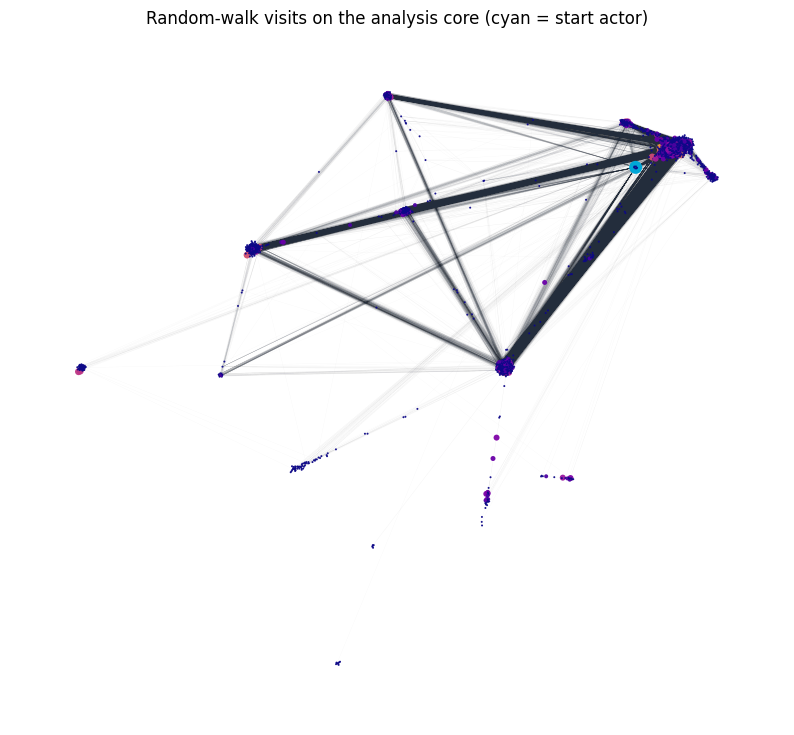

In [17]:
import random
import numpy as np
import matplotlib.pyplot as plt
import igraph as ig

if 'g_lcc' not in globals():
    raise RuntimeError('Run Task 3.1 first to create g_lcc.')

def random_walk_token(graph, starting_actor, iterations, seed=42):
    """Walk to a uniformly chosen neighbor; return visits per vertex.

    starting_actor may be a vertex index or an actor ID stored in `name`.
    The starting vertex receives one count at time zero.
    """
    if iterations < 0:
        raise ValueError('iterations must be non-negative')
    if isinstance(starting_actor, (int, np.integer)):
        current = int(starting_actor)
        if not 0 <= current < graph.vcount():
            raise IndexError('starting vertex index is outside the graph')
    else:
        current = graph.vs.find(name=str(starting_actor)).index

    rng = random.Random(seed)
    visits = np.zeros(graph.vcount(), dtype=np.int64)
    visits[current] += 1
    for _ in range(iterations):
        neighbors = graph.neighbors(current)
        if not neighbors:  # possible only for a one-vertex component
            break
        current = rng.choice(neighbors)
        visits[current] += 1
    return visits

# Start at the highest-degree actor and run a reproducible 5,000-step walk.
degrees_lcc = np.asarray(g_lcc.degree())
start_index = int(np.argmax(degrees_lcc))
start_actor = g_lcc.vs[start_index]['name']
N_STEPS = 5_000
token_visits = random_walk_token(g_lcc, start_actor, N_STEPS, seed=42)
print(f'Start actor: {start_actor}')
print(f'Total visits (including the initial token): {token_visits.sum():,}')
print(f'Actors visited: {np.count_nonzero(token_visits):,} of {g_lcc.vcount():,}')
top_visit_ids = np.argsort(token_visits)[::-1][:10]
print('Most visited actors:', [(g_lcc.vs[i]['name'], int(token_visits[i])) for i in top_visit_ids])

# Show visit counts on the manageable Task 1.3 core using its saved layout.
if 'H_und' in globals() and 'layouts' in globals() and 'drl' in layouts:
    visits_by_name = dict(zip(g_lcc.vs['name'], token_visits))
    core_visits = np.asarray([visits_by_name.get(name, 0) for name in H_und.vs['name']])
    log_visits = np.log1p(core_visits)
    normalized = log_visits / max(float(log_visits.max()), 1.0)
    colors = [(*plt.cm.plasma(value)[:3], 0.95) for value in normalized]
    sizes = 2 + 8 * np.sqrt(normalized)
    core_names = H_und.vs['name']
    if start_actor in core_names:
        seed_id = core_names.index(start_actor)
        colors[seed_id], sizes[seed_id] = '#00a6d6', 13
    fig, ax = plt.subplots(figsize=(10, 9))
    ig.plot(H_und, target=ax, layout=layouts['drl'], vertex_color=colors,
            vertex_size=list(sizes), vertex_frame_width=0, vertex_label=None,
            edge_color='rgba(35, 45, 60, 0.035)', edge_width=0.2)
    ax.set_title('Random-walk visits on the analysis core (cyan = start actor)')
    plt.show()
else:
    top = top_visit_ids[::-1]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(range(len(top)), token_visits[top], color='slateblue')
    ax.set_xticks(range(len(top)), [g_lcc.vs[i]['name'] for i in top], rotation=60, ha='right')
    ax.set_ylabel('Token visits')
    ax.set_title('Top visited actors')
    plt.tight_layout()
    plt.show()

In [24]:
deg_lcc = np.asarray(g_lcc.degree())
visited = token_visits > 0
total = token_visits.sum()

summary_32 = pd.Series({
    'start actor': start_actor,
    'steps': N_STEPS,
    'total visits (incl. start)': int(total),
    'distinct actors visited': int(visited.sum()),
    'share of network visited': round(visited.mean(), 4),
    'repeat visits': int(total - visited.sum()),
    'start actor visit share': round(token_visits[start_index] / total, 4),
    'start actor expected share (degree / 2m)': round(deg_lcc[start_index] / deg_lcc.sum(), 4),
})
display(summary_32.to_frame('value'))

top = np.argsort(token_visits)[::-1][:10]
display(pd.DataFrame({
    'actor': [g_lcc.vs[i]['name'] for i in top],
    'visits': token_visits[top],
    'observed share': (token_visits[top] / total).round(4),
    'degree': deg_lcc[top],
    'expected share': (deg_lcc[top] / deg_lcc.sum()).round(4),
}))

,value
start actor,1006419421244678144
steps,5000
total visits (incl. start),5001
distinct actors visited,3141
share of network visited,0.005
repeat visits,1860
start actor visit share,0.0454
start actor expected share (degree / 2m),0.0435


,actor,visits,observed share,degree,expected share
0,1006419421244678144,227,0.0454,105573,0.0435
1,15088481,57,0.0114,19573,0.0081
2,813286,55,0.0110,27243,0.0112
3,18590012,55,0.0110,13922,0.0057
4,29417177,35,0.0070,6733,0.0028
5,948683648,30,0.0060,468,0.0002
6,14266598,29,0.0058,10695,0.0044
7,14159148,26,0.0052,11080,0.0046
8,379408088,24,0.0048,6282,0.0026
9,755057897583804416,24,0.0048,8029,0.0033


#### Observations

The token was counted 5,001 times (including the start) but visited only 3,141 distinct actors (about 0.5%), so it revisited many actors (about 1,860 repeat visits). The start hub received the most visits (227, about 4.5% of the walk). This matches the long-run behaviour of a random walk, where visit frequency is proportional to degree: the hub's share of all degree is 105,573 / (2 × 1,214,006) ≈ 4.3%. The second most visited actor (813286, degree 27,243) also matches, with about 1.1% expected and 55 of 5,001 visits observed. Most neighbours of a hub have few other links, so the token often returns straight to the hub. 5,000 steps is far too short to cover a graph of this size.

The function is not just a technical exercise. A random walk can model a single item passed on from person to person (for example a rumour or chain message forwarded to one random contact at a time), or a user browsing the network by following retweet links. Visit counts then show which accounts are most easily reached, similar to PageRank-style importance. It ignores edge direction and weights, so it is a simplified model, not a replay of real retweet behaviour.

### Task 3.3 Information difusion process simulation

Informed after 15 iterations (beta=0.02): 156,635 of 631,488 actors


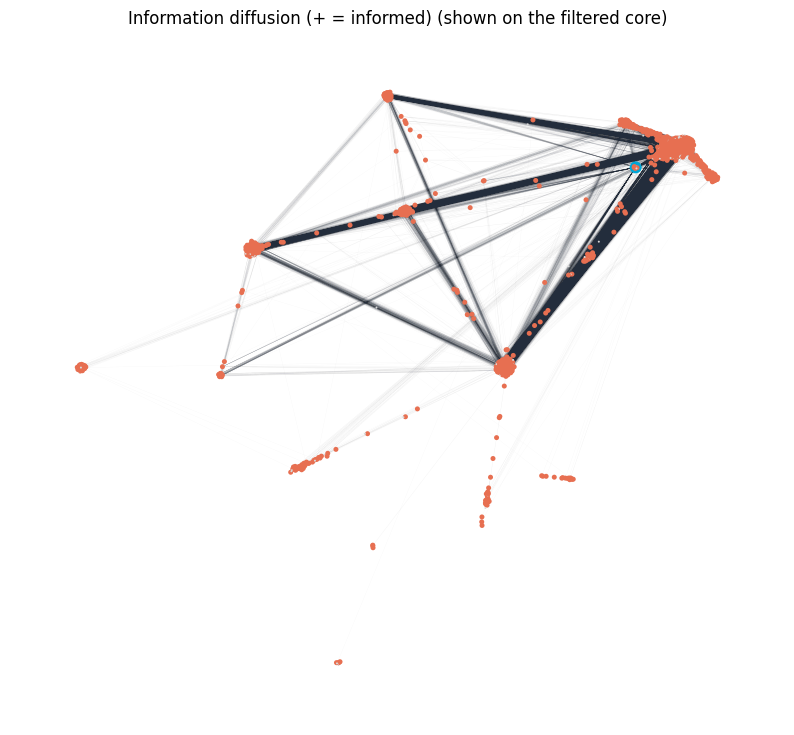

In [19]:
import random
import numpy as np
import matplotlib.pyplot as plt
import igraph as ig

if 'g_lcc' not in globals():
    raise RuntimeError('Run Task 3.1 first to create g_lcc.')

def information_diffusion(
    graph, starting_actor, iterations, beta, seed=42, return_state=False
): 
    """Simulate synchronous information spread and return the informed count."""
    if not 0 <= beta <= 1:
        raise ValueError('beta must be between 0 and 1')
    if iterations < 0:
        raise ValueError('iterations must be non-negative')
    if isinstance(starting_actor, (int, np.integer)):
        start = int(starting_actor)
        if not 0 <= start < graph.vcount():
            raise IndexError('starting vertex index is outside the graph')
    else:
        start = graph.vs.find(name=str(starting_actor)).index

    rng = random.Random(seed)
    informed = np.zeros(graph.vcount(), dtype=bool)
    informed[start] = True

    for _ in range(iterations):
        newly_informed = set()
        # Use only actors informed at the start of this round.
        for actor in np.flatnonzero(informed):
            for neighbor in graph.neighbors(int(actor)):
                if not informed[neighbor] and neighbor not in newly_informed:
                    if rng.random() < beta:
                        newly_informed.add(neighbor)
        if not newly_informed:
            break
        informed[list(newly_informed)] = True

    count = int(informed.sum())
    return (count, informed) if return_state else count

def plot_binary_state_on_core(source_graph, state, title, highlighted_actor=None):
    """Plot on the Task 1.3 core, or show state counts if it is unavailable."""
    if 'H_und' not in globals():
        positive_count = int(np.count_nonzero(state))
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.bar(['negative', 'positive'], [len(state) - positive_count, positive_count],
               color=['#d9d9d9', '#e76f51'])
        ax.set_title(title + ' (state counts; Task 1.3 core not loaded)')
        plt.tight_layout()
        plt.show()
        return
    state_by_name = dict(zip(source_graph.vs['name'], state))
    core_state = [bool(state_by_name.get(name, False)) for name in H_und.vs['name']]
    colors = ['#e76f51' if active else '#d9d9d9' for active in core_state]
    sizes = [5 if active else 2 for active in core_state]
    if highlighted_actor is not None and highlighted_actor in H_und.vs['name']:
        seed_id = H_und.vs['name'].index(highlighted_actor)
        colors[seed_id], sizes[seed_id] = '#00a6d6', 12
    layout_map = globals().get('layouts', {})
    if 'drl' not in layout_map:
        layout_map['drl'] = H_und.layout('drl')
        globals()['layouts'] = layout_map
    fig, ax = plt.subplots(figsize=(10, 9))
    ig.plot(
        H_und, target=ax, layout=layout_map['drl'],
        vertex_color=colors, vertex_size=sizes,
        vertex_frame_width=0, vertex_label=None,
        edge_color='rgba(35, 45, 60, 0.035)', edge_width=0.2,
    )
    ax.set_title(title + ' (shown on the filtered core)')
    plt.show()

start_index_33 = int(np.argmax(np.asarray(g_lcc.degree())))
start_actor_33 = g_lcc.vs[start_index_33]['name']
BETA = 0.02
ITERATIONS_33 = 15
informed_count, informed_state = information_diffusion(
    g_lcc, start_actor_33, ITERATIONS_33, BETA, seed=42, return_state=True
)
print(
    f'Informed after {ITERATIONS_33} iterations (beta={BETA}): '
    f'{informed_count:,} of {g_lcc.vcount():,} actors'
)
plot_binary_state_on_core(
    g_lcc, informed_state, 'Information diffusion (+ = informed)', start_actor_33
)

In [23]:
N = g_lcc.vcount()

# the same seed gives the same run, so these are consecutive points of one trajectory
rounds = [1, 3, 5, 10, 15]
by_round = pd.Series({t: information_diffusion(g_lcc, start_actor_33, t, BETA, seed=42) for t in rounds},
                     name='informed actors').to_frame()
by_round['share'] = (by_round['informed actors'] / N).round(3)
display(by_round.rename_axis('iterations'))

betas = [0.005, 0.01, 0.02, 0.05]
by_beta = pd.Series({b: information_diffusion(g_lcc, start_actor_33, ITERATIONS_33, b, seed=42) for b in betas},
                    name='informed actors').to_frame()
by_beta['share'] = (by_beta['informed actors'] / N).round(3)
display(by_beta.rename_axis('beta'))

,informed actors,share
iterations,,
1,2091,0.003
3,11036,0.017
5,32073,0.051
10,95931,0.152
15,156635,0.248


,informed actors,share
beta,,
0.005,26993,0.043
0.010,74169,0.117
0.020,156635,0.248
0.050,331290,0.525


#### Observations

With β = 0.02 and 15 rounds, the information reached 156,635 actors. The number can only grow, since informed actors never become uninformed. Two things shape the result:

A slow per-edge rate. Each informed actor passes the information to each uninformed neighbour with only a small chance per round, and it retries every round. A neighbour of an informed actor is therefore informed within 15 rounds that is close to the 24.8% that we observed, though the match is only a rough check. It suggests the spread is limited mainly by the transmission rate rather than by the structure of the network.
The hub helps early on. Starting at the biggest hub gives a large first wave, and the newly informed actors seed further spread.

It is a single run with seed 42, so the exact number would vary between runs. Repeating it over several seeds, different β values and different start actors (a hub versus a random account) would make the observation much stronger.

### Task 3.4 Opinion difusion process simulation

Positive actors after 20 iterations (threshold=0.5): 0 of 631,488; started with 500


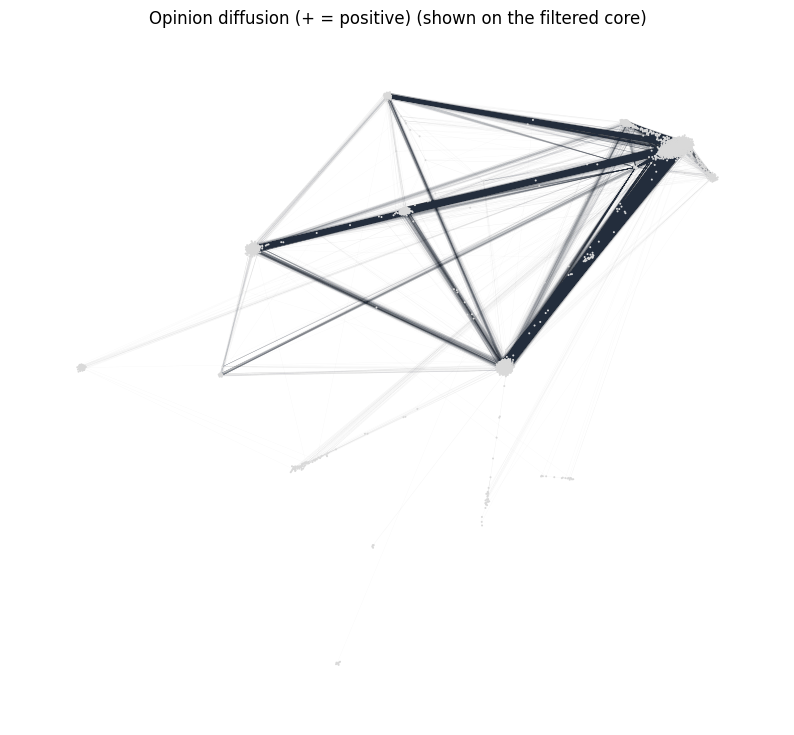

In [20]:
import random
import numpy as np
import matplotlib.pyplot as plt
import igraph as ig

if 'g_lcc' not in globals():
    raise RuntimeError('Run Task 3.1 first to create g_lcc.')

def opinion_diffusion(
    graph, n_positive, iterations, th, seed=42, return_state=False
): 
    """Synchronous threshold model: positive actors may switch to negative."""
    if not 0 <= th <= 1:
        raise ValueError('th must be between 0 and 1')
    if not 0 <= n_positive <= graph.vcount():
        raise ValueError('n_positive must be between 0 and the graph order')
    if iterations < 0:
        raise ValueError('iterations must be non-negative')

    rng = random.Random(seed)
    positive = np.zeros(graph.vcount(), dtype=bool)
    positive[rng.sample(range(graph.vcount()), n_positive)] = True

    for _ in range(iterations):
        switch_to_negative = []
        # Decisions use the same state snapshot; switches happen after the round.
        for actor in np.flatnonzero(positive):
            neighbors = graph.neighbors(int(actor))
            if not neighbors:
                continue
            negative_share = sum(not positive[n] for n in neighbors) / len(neighbors)
            if negative_share >= th:
                switch_to_negative.append(int(actor))
        if not switch_to_negative:
            break
        positive[switch_to_negative] = False

    count = int(positive.sum())
    return (count, positive) if return_state else count

INITIAL_POSITIVE = min(500, g_lcc.vcount())
THRESHOLD = 0.5
ITERATIONS_34 = 20
positive_count, positive_state = opinion_diffusion(
    g_lcc, INITIAL_POSITIVE, ITERATIONS_34, THRESHOLD,
    seed=42, return_state=True,
)
print(
    f'Positive actors after {ITERATIONS_34} iterations (threshold={THRESHOLD}): '
    f'{positive_count:,} of {g_lcc.vcount():,}; started with {INITIAL_POSITIVE:,}'
)
if 'plot_binary_state_on_core' in globals():
    plot_binary_state_on_core(
        g_lcc, positive_state, 'Opinion diffusion (+ = positive)'
    )
else:
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.bar(['negative', 'positive'],
           [g_lcc.vcount() - positive_count, positive_count],
           color=['#d9d9d9', '#e76f51'])
    ax.set_title('Final opinion counts')
    plt.tight_layout()
    plt.show()

In [25]:
N = g_lcc.vcount()
fractions = [0.01, 0.1, 0.5, 0.9]
thresholds = [0.5, 0.8, 1.0]

rows = []
for f in fractions:
    for th in thresholds:
        n0 = int(f * N)
        final = opinion_diffusion(g_lcc, n0, 10, th, seed=42)
        rows.append({'initial + share': f, 'th': th, 'initial +': n0, 'final +': final,
                     'final share of initial': round(final / n0, 3)})
display(pd.DataFrame(rows).pivot(index='initial + share', columns='th', values='final share of initial'))

th,0.5,0.8,1.0
initial + share,,,
0.01,0.000,0.001,0.022
0.10,0.000,0.011,0.168
0.50,0.007,0.568,0.578
0.90,0.804,0.865,0.865


### Observations

Starting with 500 random + actors (0.08% of the network), none were left after 20 iterations. A + actor switches to − when the share of its − neighbours is at least th, and − actors never switch back, so + can only decrease. Almost every random seed has only − neighbours (share = 100%), which is at least th for any th ≤ 1, so they all switch in the first round. A + opinion can only survive if many actors start as + or if + actors are clustered, so that they have + neighbours.